# Clase 8 — De la tabla a la red: aproximación y DQN

**RL a ciegas** · curso de aprendizaje por refuerzo (*reinforcement learning*, RL) · vía profunda

Basado en Sutton & Barto, cap. 9 (aproximación de funciones) y 11.3 (la tríada mortal), en Stanford CS234 (Brunskill), clase 4 (segunda mitad), y CS224R, clase 6, en Mnih et al. (2015) para DQN y en Machado et al. (2018) para comparar agentes.

**La pregunta de hoy:** si cada pantalla de un videojuego es un estado distinto, ¿cómo cabe la tabla $Q$? ¿Y qué se gana y qué se pierde al reemplazarla por una red?

En la clase 6 el agente guardaba lo que sabía en una tabla $Q(s, a)$: 60 casillas × 4 flechas. En la clase 7 vimos que en Atari esa tabla no tiene dónde caber. Hoy la reemplazamos por una **red neuronal** que recibe una descripción de la casilla y devuelve los cuatro valores. Vamos a ver:

1. **$Q$ como matriz y como función**: la tabla es una imagen.
2. **Una red con entrada *one-hot* es la tabla**: lo comprobamos con números.
3. **Generalizar**: con coordenadas, la red estima valores en casillas que casi no visitó.
4. **Cuando generalizar engaña**: dos vecinas separadas por una pared.
5. **Q-learning con red**: el objetivo se mueve, y los valores se disparan.
6. **DQN**: memoria de repetición y red objetivo, con y sin cada una.
7. **Comparar de forma justa**: varias semillas y curvas con dispersión.

Y un ejercicio: sacar la red objetivo o la memoria y mirar qué pasa.

> Cómo usar este notebook: ejecutar las celdas en orden (Colab: *Entorno de ejecución → Ejecutar todas*). Usa PyTorch en CPU y tarda alrededor de dos minutos.

## Preparación

La primera celda escribe el archivo `cave_env.py` con **la cueva** de todo el curso. Así el notebook funciona solo, también en Colab. No hace falta leerla.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Importamos la cueva, NumPy, Matplotlib y **PyTorch** (en Colab ya viene instalado), y fijamos las convenciones de las clases 3 a 6: **+1 al entrar a la salida**, la salida es absorbente y vale 0, el primer paso no se descuenta y $\gamma = 0{,}99$. Las partidas duran como mucho 200 pasos.

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from cave_env import CaveEnv, ACTION_NAMES

T0 = time.time()
SEMILLA = 0
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
torch.set_num_threads(1)      # con redes tan chicas, un solo hilo es más rápido
GAMMA = 0.99
env = CaveEnv(max_steps=200)

La celda siguiente define las **herramientas**: la respuesta correcta con el mapa, la red, el DQN y los dibujos. Está plegada: no hace falta leerla, solo ejecutarla.

Como en la clase 6, el agente que aprende (`dqn`) solo usa `env.reset` y `env.step`. El mapa (`env.P`, `env.R`) lo usa `iteracion_de_valor`, que calcula la respuesta correcta para comparar.

In [3]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
import matplotlib.patheffects as pe

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5,
    "lines.linewidth": 2, "axes.axisbelow": True,
})
SOMBRA = [pe.withStroke(linewidth=2.5, foreground="black")]


# ---------- la respuesta correcta (esto SÍ usa el mapa) ----------
def iteracion_de_valor(env, gamma, tol=1e-12):
    """Clase 4: V(s) <- max_a [R(s,a) + γ Σ P(s'|s,a) V(s')]. Devuelve V* y Q* (con Q* = 0 en la salida)."""
    V = np.zeros(env.nS)
    while True:
        V_nuevo = (env.R + gamma * env.P @ V).max(axis=1)
        if np.max(np.abs(V_nuevo - V)) < tol:
            Q = env.R + gamma * env.P @ V_nuevo
            Q[env.goal] = 0.0
            return V_nuevo, Q
        V = V_nuevo


def pasos_de(v, gamma=0.99):
    """Si el único premio es el +1 al entrar, V = γ^(n−1): un camino de n pasos."""
    return 1 + np.log(np.maximum(v, 1e-12)) / np.log(gamma)


def acciones_optimas(Q_estrella):
    """Máscara [s, a]: True si a es óptima en s (puede haber empates)."""
    return np.isclose(Q_estrella, Q_estrella.max(axis=1, keepdims=True), rtol=0, atol=1e-9)


# ---------- tabla y red one-hot con las mismas transiciones ----------
def transiciones_al_azar(env, n, semilla=0):
    """n transiciones (s, a, r, s', entró a la salida): casilla al azar (no la salida), flecha al azar, un paso."""
    rng = np.random.default_rng(semilla); out = []
    for _ in range(n):
        env.reset()
        s = int(rng.integers(env.nS - 1)); s = s if s < env.goal else s + 1; env.s = s
        a = int(rng.integers(env.nA))
        s2, r, fin, info = env.step(a)
        out.append((s, a, r, s2, info["reached_goal"]))
    return out


def q_tabla(env, transiciones, alfa, gamma):
    """Q-learning tabular (clase 6) sobre una lista fija de transiciones."""
    Q = np.zeros((env.nS, env.nA))
    for s, a, r, s2, fin in transiciones:
        y = r if fin else r + gamma * Q[s2].max()
        Q[s, a] += alfa * (y - Q[s, a])
    return Q


def red_one_hot(env):
    """Una capa lineal sin sesgo: entra el one-hot de la casilla (60 números), salen 4. Pesos en 0."""
    red = nn.Linear(env.nS, env.nA, bias=False).double()
    nn.init.zeros_(red.weight)
    return red


def q_red_one_hot(env, transiciones, alfa, gamma):
    """La misma lista de transiciones, pero con una red one-hot entrenada por descenso por gradiente (SGD, tasa α),
    pérdida ½ (Q(s,a) − objetivo)². Devuelve la red y su matriz de salidas (60 × 4)."""
    red = red_one_hot(env)
    opt = torch.optim.SGD(red.parameters(), lr=alfa)
    X = torch.eye(env.nS, dtype=torch.float64)              # fila s = one-hot de s
    for s, a, r, s2, fin in transiciones:
        with torch.no_grad():
            y = r if fin else r + gamma * red(X[s2]).max().item()
        perdida = 0.5 * (red(X[s])[a] - y) ** 2
        opt.zero_grad(); perdida.backward(); opt.step()
    with torch.no_grad():
        return red, red(X).numpy()


# ---------- redes con capas ocultas ----------
def entradas(env, obs):
    """Matriz (casillas × números de entrada) con la observación de cada casilla."""
    return torch.from_numpy(np.stack([env.observe(s, kind=obs) for s in range(env.nS)]))


def crear_red(n_entrada, oculta=64):
    """Perceptrón multicapa (MLP): n_entrada -> 64 -> 64 -> 4."""
    return nn.Sequential(nn.Linear(n_entrada, oculta), nn.ReLU(),
                         nn.Linear(oculta, oculta), nn.ReLU(),
                         nn.Linear(oculta, 4))


def n_parametros(red):
    return sum(p.numel() for p in red.parameters())


def ajustar(env, obs, Q_objetivo, casillas, semilla=0, iteraciones=2000, lr=3e-3):
    """Regresión: la red aprende Q_objetivo SOLO en las casillas indicadas (Adam, error cuadrático).
    Devuelve la red y sus Q en todas las casillas."""
    X = entradas(env, obs)
    torch.manual_seed(semilla)
    red = crear_red(X.shape[1])
    opt = torch.optim.Adam(red.parameters(), lr=lr)
    Y = torch.tensor(Q_objetivo, dtype=torch.float32)
    m = torch.from_numpy(np.asarray(casillas))
    for _ in range(iteraciones):
        perdida = ((red(X[m]) - Y[m]) ** 2).mean()
        opt.zero_grad(); perdida.backward(); opt.step()
    with torch.no_grad():
        return red, red(X).numpy()


# ---------- evaluar una política sin explorar ----------
SIGUIENTE = None
def pasos_hasta_salir(env, Q, max_pasos=100):
    """Para cada casilla: cuántos pasos tarda la política greedy (la flecha de mayor Q) en salir; max_pasos = no sale.
    Usa la tabla de movimientos de la cueva solo para medir, no para aprender."""
    global SIGUIENTE
    if SIGUIENTE is None:
        SIGUIENTE = np.array([[env._move(s, a)[0] for a in range(env.nA)] for s in range(env.nS)])
    flecha = Q.argmax(axis=1); res = np.zeros(env.nS, int)
    for s0 in range(env.nS):
        s, t = s0, 0
        while s != env.goal and t < max_pasos:
            s = SIGUIENTE[s, flecha[s]]; t += 1
        res[s0] = t if s == env.goal else max_pasos
    return res


def camino_greedy(env, Q, max_pasos=100):
    s = env.reset(); camino = [s]
    for _ in range(max_pasos):
        s, r, fin, info = env.step(int(Q[s].argmax())); camino.append(s)
        if info["reached_goal"]:
            break
    return camino


# ---------- DQN (y Q-learning con red sin trucos) ----------
def epsilon(paso, decae=4000, eps_fin=0.1):
    """ε decreciente: de 1 a eps_fin en `decae` pasos, y después queda fijo."""
    return max(eps_fin, 1 - (1 - eps_fin) * paso / decae)


def dqn(env, usar_replay=True, usar_objetivo=True, semilla=0, pasos=10_000, obs="coords+touch",
        lr=1e-3, lote=256, cada=4, copiar_cada=40, capacidad=10_000, calentamiento=500, decae=4000,
        eps_fin=0.1, evaluar_cada=250, gamma=0.99):
    """Q-learning con una red. Cada partida empieza en una casilla al azar (como en la clase 6, sección 5).
    Cada `cada` pasos, un paso de gradiente sobre (objetivo − Q(s,a))², con objetivo = r + γ max Q(s', ·)
    (o r si entró a la salida):
      usar_replay=True:   el lote son `lote` transiciones al azar de la memoria (las últimas `capacidad`).
      usar_replay=False:  el lote son las últimas `cada` transiciones, en orden (lo que acaba de vivir).
      usar_objetivo=True: el max Q(s', ·) del objetivo sale de una copia congelada de la red, que se pone al día
                          cada `copiar_cada` pasos.
      usar_objetivo=False: sale de la misma red que se está entrenando.
    Cada `evaluar_cada` pasos mide, sin explorar: error medio |max Q − V*|, el Q más grande y desde qué fracción
    de las casillas sale la política greedy."""
    torch.manual_seed(semilla); rng = np.random.default_rng(semilla)
    X = entradas(env, obs)
    red = crear_red(X.shape[1]); red_obj = crear_red(X.shape[1])
    red_obj.load_state_dict(red.state_dict())
    opt = torch.optim.Adam(red.parameters(), lr=lr)
    S = np.zeros(capacidad, np.int64); S2 = np.zeros_like(S); A = np.zeros_like(S)
    R = np.zeros(capacidad, np.float32); F = np.zeros(capacidad, np.float32)
    n, n_grad = 0, 0
    hist = {"paso": [], "error": [], "max_q": [], "sale": [], "pasos_S": []}
    with torch.no_grad():
        Qs = red(X).numpy()
    def nueva_partida():
        env.reset(); s = int(rng.integers(env.nS - 1)); s = s if s < env.goal else s + 1; env.s = s
        return s
    s = nueva_partida()
    for paso in range(1, pasos + 1):
        # actuar con ε-greedy
        a = int(rng.integers(env.nA)) if rng.random() < epsilon(paso, decae, eps_fin) else int(Qs[s].argmax())
        s2, r, fin, info = env.step(a)
        i = n % capacidad
        S[i], A[i], R[i], S2[i], F[i] = s, a, r, s2, float(info["reached_goal"])
        n += 1
        # aprender
        if paso % cada == 0 and (n >= calentamiento or not usar_replay):
            idx = rng.integers(min(n, capacidad), size=lote) if usar_replay else np.arange(n - cada, n) % capacidad
            with torch.no_grad():
                q_sig = (red_obj if usar_objetivo else red)(X[S2[idx]]).max(dim=1).values
                y = torch.from_numpy(R[idx]) + gamma * (1 - torch.from_numpy(F[idx])) * q_sig
            q_sa = red(X[S[idx]]).gather(1, torch.from_numpy(A[idx])[:, None]).squeeze(1)
            perdida = ((q_sa - y) ** 2).mean()
            opt.zero_grad(); perdida.backward(); opt.step(); n_grad += 1
            with torch.no_grad():
                Qs = red(X).numpy()
            if usar_objetivo and n_grad % (copiar_cada // cada) == 0:
                red_obj.load_state_dict(red.state_dict())
        s = nueva_partida() if fin else s2
        # medir (sin explorar)
        if paso % evaluar_cada == 0:
            ph = pasos_hasta_salir(env, Qs)
            hist["paso"].append(paso); hist["error"].append(np.abs(Qs.max(axis=1) - V_estrella)[ng].mean())
            hist["max_q"].append(Qs[ng].max()); hist["sale"].append(np.mean(ph[ng] < 100)); hist["pasos_S"].append(ph[env.start])
    out = {k: np.array(v) for k, v in hist.items()}
    out.update(Q=Qs, red=red, n_grad=n_grad)
    return out


def final(res, clave="sale", ultimas=4):
    """Promedio de las últimas evaluaciones (las del último millar de pasos)."""
    return float(np.mean(res[clave][-ultimas:]))


# ---------- dibujos ----------
def plot_cave(env, values=None, policy=None, path=None, ax=None, title=None, cmap="magma", clim=None, mark=None):
    """env.plot + escala de color elegible (calculada sin la salida), flechas con borde y círculos opcionales."""
    ax = env.plot(values=values, policy=policy, path=path, ax=ax, title=title, cmap=cmap)
    if values is not None:
        if clim is None:
            v = np.asarray(values, dtype=float)[np.arange(env.nS) != env.goal]
            clim = (v.min(), v.max())
        ax.images[-1].set_clim(*clim)
    for t in ax.texts:
        t.set_path_effects(SOMBRA)
    if mark is not None:
        for m in np.atleast_1d(mark):
            r, c = env.free[int(m)]
            ax.plot(c, r, "o", mfc="none", mec="#00e5ff", mew=2.5, ms=15)
    return ax


def banda(ax, x, Y, color, label, ls="-", lim=(0, 100)):
    """Promedio sobre semillas y banda de ± 1 desvío (recortada a los valores posibles)."""
    m, sd = Y.mean(0), Y.std(0)
    ax.plot(x, m, color=color, label=label, ls=ls)
    ax.fill_between(x, np.clip(m - sd, *lim), np.clip(m + sd, *lim), color=color, alpha=0.18, lw=0)


def banda_log(ax, x, Y, color, label):
    """Para escalas log: la mediana y una banda del mínimo al máximo entre semillas."""
    ax.plot(x, np.median(Y, 0), color=color, label=label)
    ax.fill_between(x, Y.min(0), Y.max(0), color=color, alpha=0.18, lw=0)

## 1. $Q$ como matriz y como función

### Paso 1 — La tabla es una imagen

Calculamos $Q^*$ con el mapa, por iteración de valor (clase 4), y lo dibujamos de dos maneras. A la izquierda, **como matriz**: una fila por casilla, una columna por flecha (4); cada número es un color. A la derecha, el mismo contenido sobre la cueva: $V^*(s) = \max_a Q^*(s,a)$ y la mejor flecha.

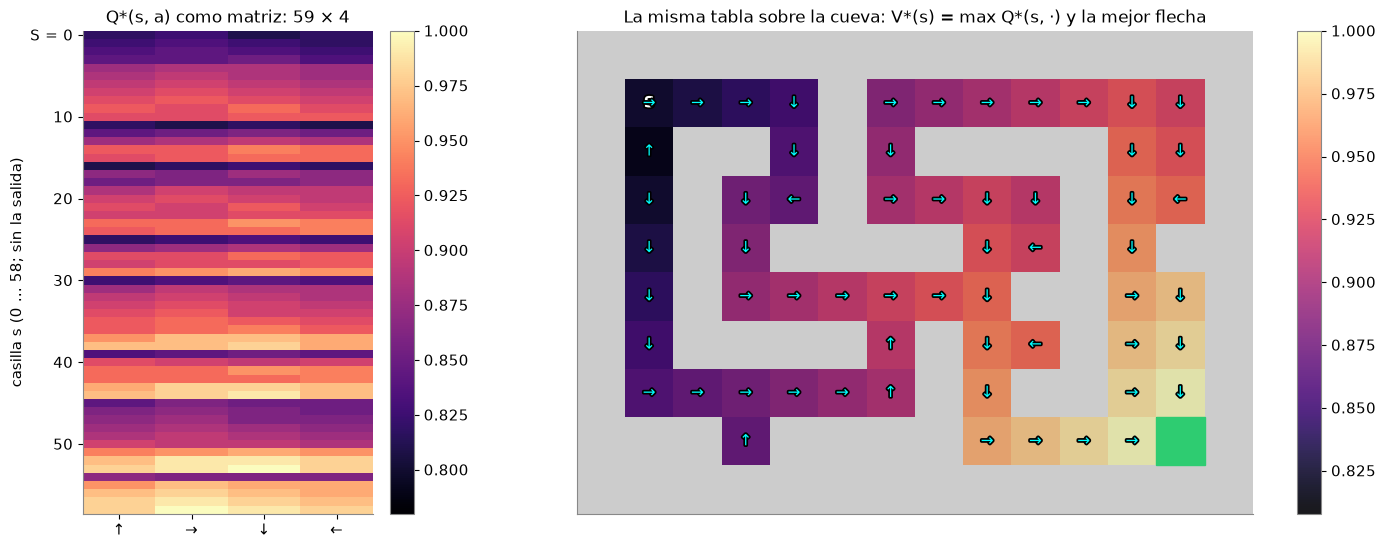

Q* es una matriz de 60 × 4 = 240 números (la fila de la salida vale 0).
V* fuera de la salida va de 0.8179 (casilla (2, 1), a 21 pasos) a 1.0000 (al lado de la salida, a 1 paso).  V*(S) = 0.8262, a 20 pasos
fila de (1, 1) (casilla 0):  ↑ 0.8179   → 0.8262   ↓ 0.8097   ← 0.8179
fila de (8, 11) (casilla 58):  ↑ 0.9801   → 1.0000   ↓ 0.9900   ← 0.9801


In [4]:
V_estrella, Q_estrella = iteracion_de_valor(env, GAMMA)
opt = acciones_optimas(Q_estrella)
ng = np.arange(env.nS) != env.goal
CLIM = (V_estrella[ng].min() - 0.01, 1.0)

fig, axs = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw=dict(width_ratios=[1, 2.6]))
im = axs[0].imshow(Q_estrella[ng], aspect="auto", cmap="magma", vmin=0.78, vmax=1.0, interpolation="nearest")
axs[0].set_xticks(range(env.nA)); axs[0].set_xticklabels(ACTION_NAMES); axs[0].grid(False)
axs[0].set_ylabel("casilla s (0 … 58; sin la salida)"); axs[0].set_title("Q*(s, a) como matriz: 59 × 4")
axs[0].set_yticks([0, 10, 20, 30, 40, 50]); axs[0].set_yticklabels(["S = 0", "10", "20", "30", "40", "50"])
plt.colorbar(im, ax=axs[0], fraction=0.1)
plot_cave(env, values=V_estrella, policy=Q_estrella.argmax(axis=1), ax=axs[1], clim=CLIM,
          title="La misma tabla sobre la cueva: V*(s) = max Q*(s, ·) y la mejor flecha")
plt.tight_layout(); plt.show()

print(f"Q* es una matriz de {env.nS} × {env.nA} = {Q_estrella.size} números (la fila de la salida vale 0).")
lejos = int(np.argmin(np.where(ng, V_estrella, np.inf)))
print(f"V* fuera de la salida va de {V_estrella[lejos]:.4f} (casilla {env.free[lejos]}, a {pasos_de(V_estrella[lejos]):.0f} pasos) "
      f"a {V_estrella[ng].max():.4f} (al lado de la salida, a 1 paso).  V*(S) = {V_estrella[env.start]:.4f}, "
      f"a {pasos_de(V_estrella[env.start]):.0f} pasos")
for s in [env.start, env.pos2s[(8, 11)]]:
    print(f"fila de {env.free[s]} (casilla {s}):  " + "   ".join(f"{ACTION_NAMES[a]} {Q_estrella[s, a]:.4f}" for a in range(env.nA)))

Con $\gamma = 0{,}99$ y un solo premio de +1, todos los valores están entre 0,82 y 1: las diferencias entre flechas de una misma casilla son de un 1 a un 2 %. Eso va a importar cuando una red tenga que aprenderlas.

### Paso 2 — La misma tabla, como función

Una tabla es una **función** que recibe una pregunta y devuelve un número: «¿cuánto vale la flecha $a$ en la casilla $s$?». Escrita así:

$$Q:\ (s, a) \longmapsto \text{valor} \qquad\text{o, devolviendo las cuatro flechas juntas,}\qquad Q:\ s \longmapsto \big(Q(s,\uparrow),\ Q(s,\rightarrow),\ Q(s,\downarrow),\ Q(s,\leftarrow)\big)$$

La tabla guarda un número **independiente** por pregunta y, para responder, lo busca. Una red neuronal $Q_\theta$ con parámetros $\theta$ es otra manera de escribir esa función: en vez de buscar, calcula.

In [5]:
def Q_como_funcion(fila, columna, flecha):
    s = env.pos2s[(fila, columna)]           # la casilla como número (fila de la matriz)
    a = ACTION_NAMES.index(flecha)           # la flecha como número (columna de la matriz)
    return Q_estrella[s, a]

for fila, columna, flecha in [(1, 1, "→"), (1, 1, "↓"), (8, 11, "→"), (7, 6, "↑")]:
    print(f"Q(casilla ({fila}, {columna}), {flecha}) = {Q_como_funcion(fila, columna, flecha):.4f}")

Q(casilla (1, 1), →) = 0.8262
Q(casilla (1, 1), ↓) = 0.8097
Q(casilla (8, 11), →) = 1.0000
Q(casilla (7, 6), ↑) = 0.9044


## 2. Una red con entrada *one-hot* es la tabla

### Paso 1 — La entrada *one-hot*

Para dársela a una red, la casilla tiene que ser una lista de números. La forma más simple es la codificación *one-hot*: 60 números, todos 0 salvo un 1 en la posición de la casilla (`env.observe(s, kind="onehot")`). Tomamos la red más chica posible: una capa lineal sin sesgo, $Q_\theta(s) = W\,x_s$, con $W$ de 4 × 60. Multiplicar $W$ por un *one-hot* **elige una columna**: la columna $s$ de $W$ son los cuatro valores de la casilla $s$.

In [6]:
x_S = env.observe(env.start, kind="onehot")
print(f"one-hot de S: {len(x_S)} números, suma = {x_S.sum():.0f}, el 1 está en la posición {int(x_S.argmax())}")
print("primeros 12:", x_S[:12].astype(int).tolist())

red_demo = red_one_hot(env)
with torch.no_grad():
    red_demo.weight[:, env.start] = torch.tensor([0.1, 0.2, 0.3, 0.4], dtype=torch.float64)   # una columna cualquiera
    salida = red_demo(torch.from_numpy(x_S).double()).numpy()
print(f"\nW tiene {red_demo.weight.numel()} números = {env.nS} casillas × {env.nA} flechas, los mismos que la tabla")
print("ponemos (0,1  0,2  0,3  0,4) en la columna de S; la red, con el one-hot de S, devuelve:", salida.round(2).tolist())

one-hot de S: 60 números, suma = 1, el 1 está en la posición 0
primeros 12: [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

W tiene 240 números = 60 casillas × 4 flechas, los mismos que la tabla
ponemos (0,1  0,2  0,3  0,4) en la columna de S; la red, con el one-hot de S, devuelve: [0.1, 0.2, 0.3, 0.4]


### Paso 2 — Un paso de gradiente, con números

La red aprende por descenso por gradiente (*gradient descent*), con la pérdida $\tfrac12\,(Q_\theta(s,a) - y)^2$, donde $y$ es el objetivo de Q-learning de la clase 6: $y = r + \gamma \max_{a'} Q_\theta(s', a')$, o $y = r$ si entró a la salida. La derivada respecto de cada peso $W_{b,j}$ es $(Q_\theta(s,a) - y)\cdot x_j$ si $b = a$, y 0 si no. Con el *one-hot*, $x_j$ es 0 salvo en $j = s$, así que **solo un peso tiene gradiente**: el de la fila $a$, columna $s$.

Lo vemos con una transición que entra a la salida, partiendo de pesos en 0 y con tasa de aprendizaje $\alpha = 0{,}5$.

In [7]:
ALFA = 0.5
s, a = env.pos2s[(8, 11)], 1                       # al lado de la salida, flecha →
env.reset(); env.s = s
s2, r, fin, info = env.step(a)
print(f"transición: {env.free[s]} --{ACTION_NAMES[a]}--> {env.free[s2]}   r = {r:g}   ¿entró a la salida? {info['reached_goal']}")

red_paso = red_one_hot(env)
X1 = torch.eye(env.nS, dtype=torch.float64)
y = r                                              # entró a la salida: el objetivo es r
perdida = 0.5 * (red_paso(X1[s])[a] - y) ** 2
perdida.backward()
g = red_paso.weight.grad
print(f"pesos con gradiente distinto de 0: {int((g != 0).sum())} de {g.numel()}   (fila {ACTION_NAMES[a]}, columna {s}): "
      f"gradiente = Q − y = 0 − {y:g} = {g[a, s].item():+.1f}")
with torch.no_grad():
    red_paso.weight -= ALFA * g
print(f"paso de gradiente:  W[{ACTION_NAMES[a]}, {s}] = 0 − {ALFA} · ({g[a, s].item():+.1f}) = {red_paso.weight[a, s].item():.2f}")
Q_paso = np.zeros((env.nS, env.nA)); Q_paso[s, a] += ALFA * (y - Q_paso[s, a])
print(f"Q-learning tabular: Q({env.free[s]}, {ACTION_NAMES[a]}) = 0 + {ALFA} · ({y:g} − 0) = {Q_paso[s, a]:.2f}")

transición: (8, 11) --→--> (8, 12)   r = 1   ¿entró a la salida? True
pesos con gradiente distinto de 0: 1 de 240   (fila →, columna 58): gradiente = Q − y = 0 − 1 = -1.0
paso de gradiente:  W[→, 58] = 0 − 0.5 · (-1.0) = 0.50
Q-learning tabular: Q((8, 11), →) = 0 + 0.5 · (1 − 0) = 0.50


El paso de gradiente queda $W_{a,s} \leftarrow W_{a,s} + \alpha\,(y - W_{a,s})$: **la regla de Q-learning de la clase 6, letra por letra**.

### Paso 3 — La tabla y la red, con las mismas 20 000 transiciones

Ahora muchas transiciones: casilla al azar, flecha al azar, un paso. Las mismas 20 000, en el mismo orden, para Q-learning tabular ($\alpha = 0{,}5$) y para la red *one-hot* (SGD con tasa 0,5).

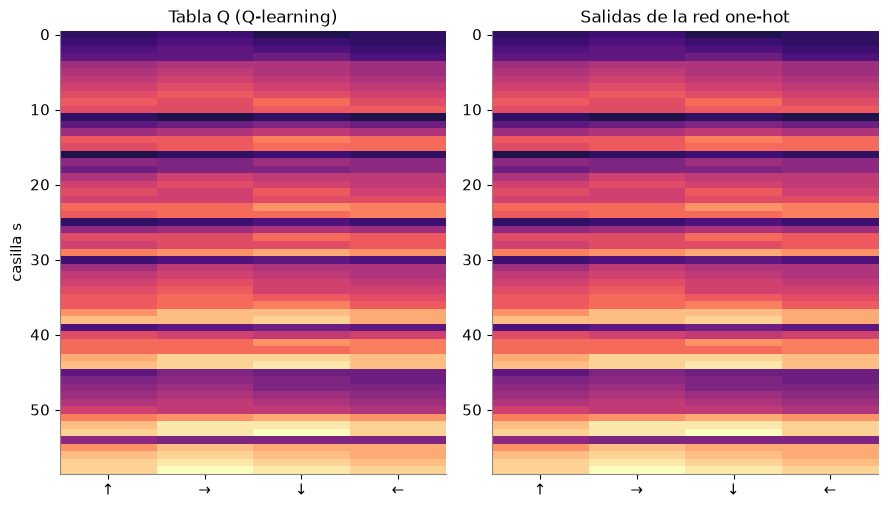

parámetros de la red: 240   números de la tabla: 240
diferencia máxima entre tabla y red: 0.0e+00
y las dos contra Q*: error máximo 0.0000; flechas óptimas en 100% de las casillas


In [8]:
trans = transiciones_al_azar(env, 20_000, semilla=SEMILLA)
Q_tab = q_tabla(env, trans, ALFA, GAMMA)
red_lineal, Q_red1 = q_red_one_hot(env, trans, ALFA, GAMMA)

fig, axs = plt.subplots(1, 2, figsize=(9, 5.2))
for ax, M, titulo in [(axs[0], Q_tab[ng], "Tabla Q (Q-learning)"), (axs[1], Q_red1[ng], "Salidas de la red one-hot")]:
    im = ax.imshow(M, aspect="auto", cmap="magma", vmin=0.78, vmax=1.0, interpolation="nearest")
    ax.set_xticks(range(env.nA)); ax.set_xticklabels(ACTION_NAMES); ax.set_title(titulo); ax.grid(False)
axs[0].set_ylabel("casilla s")
plt.tight_layout(); plt.show()

print(f"parámetros de la red: {red_lineal.weight.numel()}   números de la tabla: {Q_tab.size}")
print(f"diferencia máxima entre tabla y red: {np.abs(Q_tab - Q_red1).max():.1e}")
print(f"y las dos contra Q*: error máximo {np.abs(Q_tab - Q_estrella).max():.4f}; flechas óptimas en "
      f"{np.mean(opt[np.arange(env.nS), Q_tab.argmax(1)][ng]):.0%} de las casillas")

Las dos matrices son idénticas, número por número (diferencia máxima: 0), y las dos llegaron a $Q^*$: **Q-learning tabular es un caso particular de una red**, la que tiene un parámetro propio por casilla y flecha. Por eso tampoco gana nada: lo que aprende en una casilla no le dice nada de la de al lado. Para que la red **comparta** lo aprendido entre casillas, hay que cambiar la entrada.

## 3. Generalizar: saber algo de donde casi no estuvo

### Paso 1 — Un agente que no pasó por todos lados

Como en la clase 6, un agente juega 100 partidas desde S con Q-learning tabular, $\varepsilon = 0{,}1$ y $\alpha = 0{,}2$, y contamos cuántas veces pisa cada casilla. Llamamos **poco visitadas** a las que pisó menos de 10 veces.

In [9]:
rng = np.random.default_rng(SEMILLA)
Q_ag = rng.uniform(0, 1e-4, size=(env.nS, env.nA)); visitas = np.zeros(env.nS, int); salidas = 0
for partida in range(100):
    s = env.reset(); visitas[s] += 1
    while True:
        a = int(rng.integers(env.nA)) if rng.random() < 0.1 else int(Q_ag[s].argmax())
        s2, r, fin, info = env.step(a); visitas[s2] += 1
        y = r if info["reached_goal"] else r + GAMMA * Q_ag[s2].max()
        Q_ag[s, a] += 0.2 * (y - Q_ag[s, a]); s = s2
        if fin:
            salidas += info["reached_goal"]; break
poco = ng & (visitas < 10)
vistas = ng & ~poco
print(f"salidas en 100 partidas: {salidas}")
print(f"casillas poco visitadas (< 10 visitas): {poco.sum()} de {ng.sum()}: " + ", ".join(f"{env.free[s]}·{visitas[s]}" for s in np.flatnonzero(poco)))
print(f"casillas vistas (10 visitas o más): {vistas.sum()}")

salidas en 100 partidas: 0
casillas poco visitadas (< 10 visitas): 11 de 59: (1, 10)·5, (1, 11)·2, (1, 12)·1, (4, 11)·5, (5, 11)·0, (5, 12)·0, (6, 11)·0, (6, 12)·0, (7, 11)·0, (7, 12)·0, (8, 11)·0
casillas vistas (10 visitas o más): 48


En 100 partidas este agente no llegó nunca a la salida: las casillas poco visitadas son justamente las de alrededor de la salida y el rincón de arriba a la derecha.

### Paso 2 — Tabla contra red con coordenadas

Para mirar la generalización **sola**, sin el ruido del aprendizaje por refuerzo (eso vuelve en la sección 5), hacemos trampa a propósito: en las casillas vistas le damos a cada método el valor correcto $Q^*$, y le preguntamos por las que no vio.

1. La **tabla** (o la red *one-hot*, que es lo mismo) guarda esos números; en las otras casillas no tiene nada y se queda en 0.
2. Una **red con coordenadas**: entran 2 números, la fila y la columna divididas por el tamaño de la cueva (`env.observe(s, kind="coords")`); pasan por dos capas ocultas de 64 neuronas y salen 4. Se entrena con regresión común (Adam, error cuadrático) solo con las casillas vistas.
3. Como referencia, **adivinar el promedio**: a cada casilla no vista, el promedio de $V^*$ de las vistas.

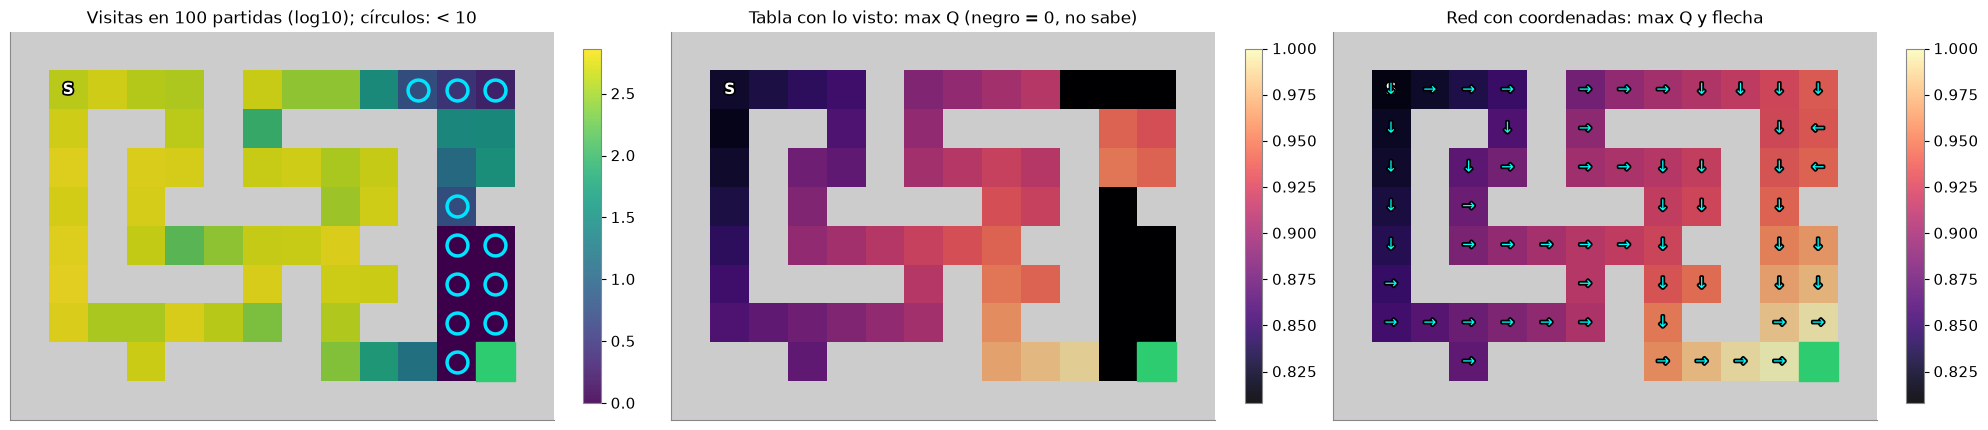

red con coordenadas: 2 -> 64 -> 64 -> 4, 4612 parámetros (la tabla: 240)
error medio |V − V*| en las 11 casillas poco visitadas:
   tabla = 0.9681   adivinar el promedio = 0.0687   red con coordenadas = 0.0106
   (en las vistas, la red se equivoca en promedio 0.0061)
flechas óptimas de la red en las poco visitadas: 82%

  casilla  visitas      V*   tabla     red   pasos hasta la salida: de verdad / según la red
  (1, 10)        5  0.9227  0.0000  0.9184       9 / 9.5
  (1, 11)        2  0.9321  0.0000  0.9271       8 / 8.5
  (1, 12)        1  0.9227  0.0000  0.9384       9 / 7.3
  (4, 11)        5  0.9606  0.0000  0.9418       5 / 7.0
  (5, 11)        0  0.9703  0.0000  0.9543       4 / 5.7
  (5, 12)        0  0.9801  0.0000  0.9645       3 / 4.6
  (6, 11)        0  0.9801  0.0000  0.9681       3 / 4.2
  (6, 12)        0  0.9900  0.0000  0.9770       2 / 3.3
  (7, 11)        0  0.9900  0.0000  0.9833       2 / 2.7
  (7, 12)        0  1.0000  0.0000  0.9957       1 / 1.4
  (8, 11)      

In [10]:
red_xy, Q_xy = ajustar(env, "coords", Q_estrella, vistas, semilla=SEMILLA)
Q_tabla_vistas = np.where(vistas[:, None], Q_estrella, 0.0)

V_xy, V_tv = Q_xy.max(axis=1), Q_tabla_vistas.max(axis=1)
err_tabla = np.abs(V_tv - V_estrella)[poco].mean()
err_prom = np.abs(V_estrella[vistas].mean() - V_estrella)[poco].mean()
err_xy = np.abs(V_xy - V_estrella)[poco].mean()

fig, axs = plt.subplots(1, 3, figsize=(20, 4.8))
plot_cave(env, values=np.log10(1 + visitas), ax=axs[0], cmap="viridis", mark=np.flatnonzero(poco),
          title="Visitas en 100 partidas (log10); círculos: < 10")
plot_cave(env, values=V_tv, ax=axs[1], clim=CLIM, title="Tabla con lo visto: max Q (negro = 0, no sabe)")
plot_cave(env, values=V_xy, policy=Q_xy.argmax(axis=1), ax=axs[2], clim=CLIM, title="Red con coordenadas: max Q y flecha")
plt.tight_layout(); plt.show()

print(f"red con coordenadas: 2 -> 64 -> 64 -> 4, {n_parametros(red_xy)} parámetros (la tabla: {env.nS * env.nA})")
print(f"error medio |V − V*| en las {poco.sum()} casillas poco visitadas:")
print(f"   tabla = {err_tabla:.4f}   adivinar el promedio = {err_prom:.4f}   red con coordenadas = {err_xy:.4f}")
print(f"   (en las vistas, la red se equivoca en promedio {np.abs(V_xy - V_estrella)[vistas].mean():.4f})")
print(f"flechas óptimas de la red en las poco visitadas: {np.mean(opt[np.arange(env.nS), Q_xy.argmax(1)][poco]):.0%}\n")
print(f"{'casilla':>9s} {'visitas':>8s} {'V*':>7s} {'tabla':>7s} {'red':>7s}   pasos hasta la salida: de verdad / según la red")
for s in np.flatnonzero(poco):
    print(f"{str(env.free[s]):>9s} {visitas[s]:>8d} {V_estrella[s]:>7.4f} {V_tv[s]:>7.4f} {V_xy[s]:>7.4f}   "
          f"{pasos_de(V_estrella[s]):>5.0f} / {pasos_de(V_xy[s]):.1f}")

La tabla no sabe nada de las casillas que no vio: su valor quedó en 0 y el error es casi el valor entero. La red con coordenadas, en cambio, da en esas casillas valores muy cerca de los verdaderos, mejor que adivinar el promedio y con la mayoría de las flechas bien: casillas con coordenadas parecidas comparten los mismos pesos, así que lo que aprendió de las vecinas vistas «se contagia». Eso es **generalizar**.

Una aclaración honesta: acá la red tiene **más** parámetros que la tabla (4612 contra 240). La ventaja no es el tamaño, sino que la cantidad de parámetros **no crece con la cantidad de casillas**: con pantallas de Atari, es la única opción.

## 4. Cuando generalizar engaña: vecinas separadas por una pared

Generalizar es suponer que casillas con entradas parecidas valen parecido. En una cueva, eso falla justo donde hay paredes.

### Paso 1 — Dos casillas parecidas para la red

Las casillas (7, 6) y (7, 8) están a dos columnas, con la pared (7, 7) en el medio. Para la red con coordenadas son casi la misma entrada; para el agente, una está a 11 pasos de la salida y la otra a 5.

In [11]:
izq, der = env.pos2s[(7, 6)], env.pos2s[(7, 8)]
for s in [izq, der]:
    x = env.observe(s, kind="coords")
    print(f"casilla {env.free[s]}: entrada = ({x[0]:.3f}, {x[1]:.3f})   V* = {V_estrella[s]:.4f}   "
          f"a {pasos_de(V_estrella[s]):.0f} pasos de la salida   mejor flecha: "
          + ", ".join(ACTION_NAMES[a] for a in np.flatnonzero(opt[s])))
d = env.observe(der, kind="coords") - env.observe(izq, kind="coords")
print(f"diferencia de entradas: ({d[0]:.3f}, {d[1]:.3f})   diferencia de V*: {V_estrella[der] - V_estrella[izq]:.4f} "
      f"(el salto más grande entre dos casillas a dos columnas de distancia)")

casilla (7, 6): entrada = (0.778, 0.462)   V* = 0.9044   a 11 pasos de la salida   mejor flecha: ↑
casilla (7, 8): entrada = (0.778, 0.615)   V* = 0.9606   a 5 pasos de la salida   mejor flecha: ↓
diferencia de entradas: (0.000, 0.154)   diferencia de V*: 0.0562 (el salto más grande entre dos casillas a dos columnas de distancia)


### Paso 2 — Aun con todas las respuestas, la red se confunde

Ahora le damos a la red con coordenadas el $Q^*$ correcto de **las 59 casillas**, sin esconderle ninguna, y miramos qué flecha elige en cada una. A la izquierda: verde, flecha óptima; rojo, no.

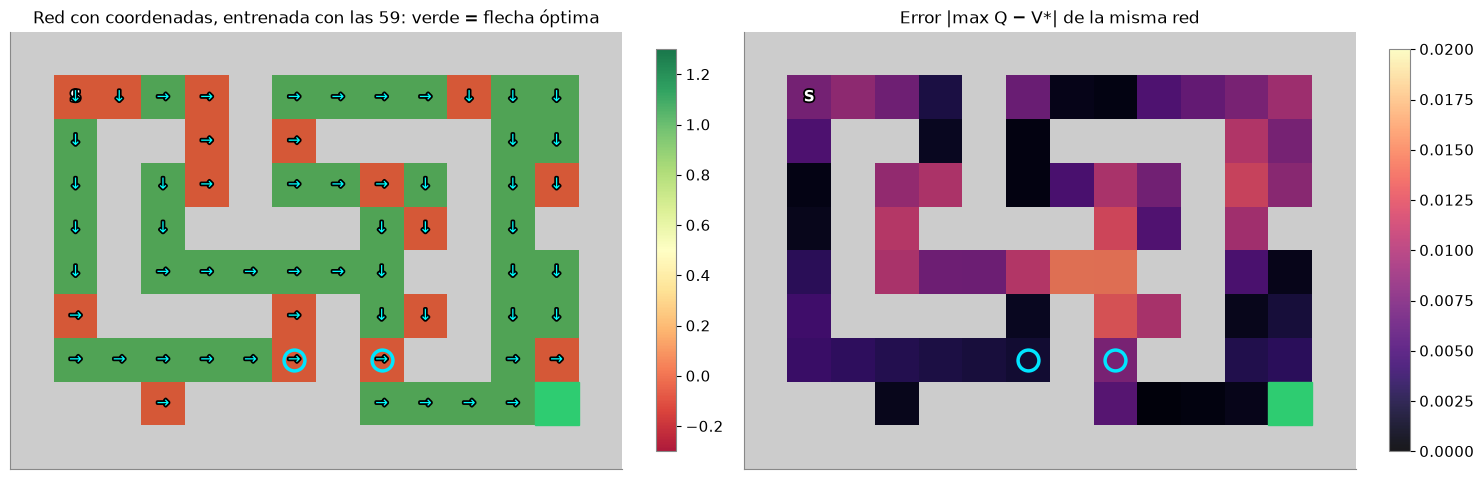

error medio |max Q − V*|: 0.0058   flechas óptimas: 71% de las casillas (17 equivocadas)

casilla (7, 6)   V* = 0.9044   red: max Q = 0.9064
   Q* :  ↑ 0.9044   → 0.8953   ↓ 0.8953   ← 0.8864
   red:  ↑ 0.9053   → 0.9064   ↓ 0.9034   ← 0.8975   -> elige → (la óptima es ↑)

casilla (7, 8)   V* = 0.9606   red: max Q = 0.9528
   Q* :  ↑ 0.9415   → 0.9510   ↓ 0.9606   ← 0.9510
   red:  ↑ 0.9449   → 0.9528   ↓ 0.9523   ← 0.9484   -> elige → (la óptima es ↓)


In [12]:
red_xy_todo, Q_xy_todo = ajustar(env, "coords", Q_estrella, ng, semilla=SEMILLA, iteraciones=3000)
bien_xy = opt[np.arange(env.nS), Q_xy_todo.argmax(axis=1)]

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
plot_cave(env, values=np.where(bien_xy, 1.0, 0.0), policy=Q_xy_todo.argmax(axis=1), ax=axs[0], cmap="RdYlGn",
          clim=(-0.3, 1.3), mark=[izq, der], title="Red con coordenadas, entrenada con las 59: verde = flecha óptima")
plot_cave(env, values=np.abs(Q_xy_todo.max(axis=1) - V_estrella) * ng, ax=axs[1], cmap="magma", clim=(0, 0.02),
          mark=[izq, der], title="Error |max Q − V*| de la misma red")
plt.tight_layout(); plt.show()

print(f"error medio |max Q − V*|: {np.abs(Q_xy_todo.max(1) - V_estrella)[ng].mean():.4f}   "
      f"flechas óptimas: {bien_xy[ng].mean():.0%} de las casillas ({int((~bien_xy & ng).sum())} equivocadas)")
for s in [izq, der]:
    print(f"\ncasilla {env.free[s]}   V* = {V_estrella[s]:.4f}   red: max Q = {Q_xy_todo[s].max():.4f}")
    print("   Q* :  " + "   ".join(f"{ACTION_NAMES[a]} {Q_estrella[s, a]:.4f}" for a in range(env.nA)))
    print("   red:  " + "   ".join(f"{ACTION_NAMES[a]} {Q_xy_todo[s, a]:.4f}" for a in range(env.nA))
          + f"   -> elige {ACTION_NAMES[int(Q_xy_todo[s].argmax())]}"
          + ("" if bien_xy[s] else f" (la óptima es {', '.join(ACTION_NAMES[a] for a in np.flatnonzero(opt[s]))})"))

El error medio del valor es chico, pero las flechas cuentan otra historia. En (7, 6) la red elige **→, contra la pared**: del otro lado, a dos columnas, está (7, 8), que vale mucho más, y para la red «ir a la derecha desde ahí» se parece a estar en (7, 8). La red no puede poner un salto brusco entre dos entradas tan parecidas, así que suaviza: le sube la flecha → a (7, 6) y le baja el valor a (7, 8). Y como en esta cueva las flechas de una casilla se diferencian en un 1 o 2 %, un error chico en el valor alcanza para elegir mal. La tabla, que no generaliza, no se equivoca así.

> **Para enseñarlo:** una red es una tabla que comparte números entre casillas: aprende más rápido de lo que no vio, y por eso también se equivoca en lo que no vio.

### Paso 3 — Una ayuda: contarle dónde hay pared

Si la entrada dice dónde hay pared, la red puede separar las dos casillas. Agregamos cuatro **bigotes** (arriba, derecha, abajo, izquierda) que valen 1 si hay pared pegada (`kind="coords+touch"`): entran 6 números, salen 4. Es la entrada que va a usar el DQN de la sección 6.

In [13]:
red_bg, Q_bg = ajustar(env, "coords+touch", Q_estrella, ng, semilla=SEMILLA, iteraciones=3000)
bien_bg = opt[np.arange(env.nS), Q_bg.argmax(axis=1)]
for s in [izq, der]:
    o = env.observe(s, kind="coords+touch")
    print(f"{env.free[s]}: entrada = ({o[0]:.3f}, {o[1]:.3f}) + bigotes " + " ".join(f"{n}:{int(b)}" for n, b in zip(ACTION_NAMES, o[2:]))
          + f"   -> elige {ACTION_NAMES[int(Q_bg[s].argmax())]} ({'óptima' if bien_bg[s] else 'NO óptima'})")
print(f"\nflechas óptimas:  coordenadas {bien_xy[ng].mean():.0%}   coordenadas + bigotes {bien_bg[ng].mean():.0%}")
print(f"error medio |max Q − V*|:  coordenadas {np.abs(Q_xy_todo.max(1) - V_estrella)[ng].mean():.4f}   "
      f"coordenadas + bigotes {np.abs(Q_bg.max(1) - V_estrella)[ng].mean():.4f}")

(7, 6): entrada = (0.778, 0.462) + bigotes ↑:0 →:1 ↓:1 ←:0   -> elige ↑ (óptima)
(7, 8): entrada = (0.778, 0.615) + bigotes ↑:0 →:1 ↓:0 ←:1   -> elige ↓ (óptima)

flechas óptimas:  coordenadas 71%   coordenadas + bigotes 97%
error medio |max Q − V*|:  coordenadas 0.0058   coordenadas + bigotes 0.0045


Con los bigotes, la red acierta la flecha en muchas más casillas. La entrada decide qué casillas «se parecen» para la red, y por lo tanto dónde generaliza bien y dónde engaña.

## 5. Q-learning con red: el objetivo se mueve

Hasta acá le dimos a la red las respuestas correctas. En RL no las tiene: el objetivo de Q-learning, $y = r + \gamma \max_{a'} Q_\theta(s', a')$, **lo calcula la misma red**. Cada paso de gradiente cambia $\theta$, y con $\theta$ cambia también el objetivo. Con la tabla no pasaba nada grave, porque tocar $Q(s,a)$ no movía $Q(s', \cdot)$. Con una red que generaliza, sí.

### Paso 1 — Un peso que persigue su propia cola

El ejemplo más chico (una variante del de Sutton y Barto, 11.2). Dos casillas: A, que la red describe con el número $x_A = 1$, y B, con $x_B = 2$. La red tiene un solo peso: $Q(A) = w \cdot 1$ y $Q(B) = w \cdot 2$. La única transición que ve es A → B, con premio 0. El objetivo para $Q(A)$ es $\gamma\, Q(B) = 2\gamma w$, y cada paso de gradiente hace

$$w \leftarrow w + \alpha\,(2\gamma w - w)\cdot 1 = \big(1 + \alpha(2\gamma - 1)\big)\, w .$$

Como $2\gamma - 1 = 0{,}98 > 0$, cada paso **agranda** $w$, y con $w$ crece el objetivo. Si además la red ve la transición B → salida (premio 1, el objetivo de $Q(B)$ es 1), el peso se frena.

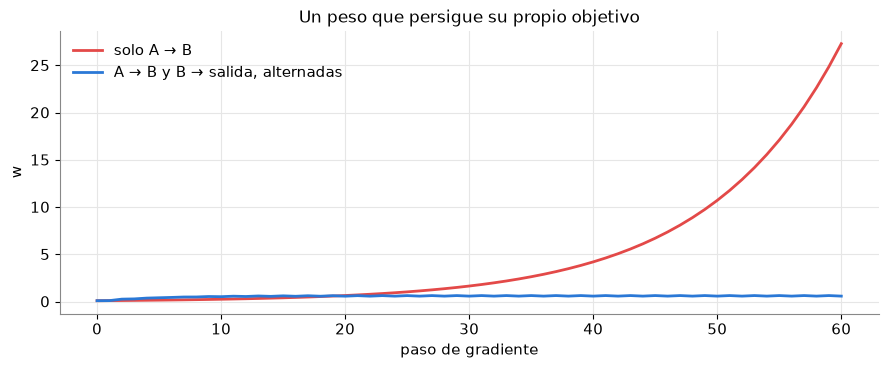

solo A → B, primeros pasos (α = 0,1):
   w = 0.1000   objetivo = γ · Q(B) = 0.99 · 0.2000 = 0.1980   w nuevo = 0.1000 + 0,1 · (0.1980 − 0.1000) = 0.1098
   w = 0.1098   objetivo = γ · Q(B) = 0.99 · 0.2196 = 0.2174   w nuevo = 0.1098 + 0,1 · (0.2174 − 0.1098) = 0.1206
   w = 0.1206   objetivo = γ · Q(B) = 0.99 · 0.2411 = 0.2387   w nuevo = 0.1206 + 0,1 · (0.2387 − 0.1206) = 0.1324
después de 60 pasos: w = 27.30 (creció × 273.0), y sigue creciendo
con las dos transiciones: w = 0.5862  ->  Q(A) = 0.5862, Q(B) = 1.1723 (los verdaderos: Q(A) = 0.99, Q(B) = 1; con un solo peso no se pueden tener los dos)


In [14]:
def un_peso(transiciones, pasos=60, alfa=0.1, w=0.1):
    hist = [w]
    for k in range(pasos):
        x, x_sig, r, fin = transiciones[k % len(transiciones)]
        y = r if fin else r + GAMMA * w * x_sig          # el objetivo usa el mismo w
        w = w + alfa * (y - w * x) * x
        hist.append(w)
    return np.array(hist)

A_B = (1.0, 2.0, 0.0, False)       # de A (x = 1) a B (x = 2), premio 0
B_sal = (2.0, 0.0, 1.0, True)      # de B a la salida, premio 1
w_solo = un_peso([A_B])
w_mezcla = un_peso([A_B, B_sal])

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(w_solo, color=COLORES[7], label="solo A → B")
ax.plot(w_mezcla, color=COLORES[0], label="A → B y B → salida, alternadas")
ax.set_xlabel("paso de gradiente"); ax.set_ylabel("w"); ax.set_title("Un peso que persigue su propio objetivo")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

print("solo A → B, primeros pasos (α = 0,1):")
w = 0.1
for k in range(3):
    y = GAMMA * w * 2
    print(f"   w = {w:.4f}   objetivo = γ · Q(B) = {GAMMA} · {2 * w:.4f} = {y:.4f}   w nuevo = {w:.4f} + 0,1 · ({y:.4f} − {w:.4f}) = {w + 0.1 * (y - w):.4f}")
    w = w + 0.1 * (y - w)
print(f"después de 60 pasos: w = {w_solo[-1]:.2f} (creció × {w_solo[-1] / w_solo[0]:.1f}), y sigue creciendo")
print(f"con las dos transiciones: w = {w_mezcla[-1]:.4f}  ->  Q(A) = {w_mezcla[-1]:.4f}, Q(B) = {2 * w_mezcla[-1]:.4f} "
      f"(los verdaderos: Q(A) = {GAMMA}, Q(B) = 1; con un solo peso no se pueden tener los dos)")

Con una sola transición el peso crece sin freno: el objetivo se escapa cada vez que la red se le acerca. Esto es lo que Sutton y Barto llaman la **tríada mortal** (*deadly triad*): **aproximación** (una red que comparte pesos) + ***bootstrapping*** (el objetivo usa la propia estimación) + **aprender *off-policy*** (de datos que no siguen la política que se evalúa; acá, siempre la misma transición). Con las tres juntas, el aprendizaje puede diverger. Con las dos transiciones mezcladas el peso se asienta (en un compromiso, porque un solo peso no alcanza para los dos valores).

### Paso 2 — En la cueva, sin trucos

Ahora la red de verdad: entrada coordenadas + bigotes, 6 → 64 → 64 → 4, Adam con tasa $10^{-3}$. Q-learning tal cual, **sin trucos**: cada 4 pasos, un paso de gradiente con las últimas 4 transiciones, y el objetivo calculado con la misma red. Exploración $\varepsilon$-greedy, con $\varepsilon$ que baja de 1 a 0,1 en los primeros 4000 pasos; cada partida empieza en una casilla al azar; 10 000 pasos.

Una pista para leer la figura: con un solo premio de +1, **ningún $Q$ verdadero puede pasar de 1**.

2500 pasos de gradiente en 3.1 s


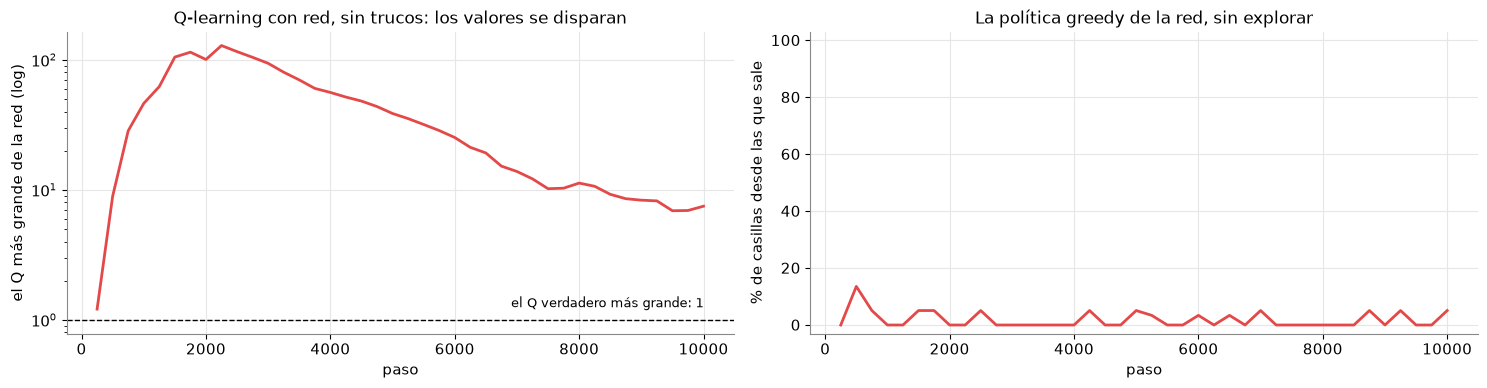

el Q más grande de la red: 1.21 en el paso 250, 128.8 en el paso 2250 (el pico), 7.5 al final
error medio |max Q − V*| al final: 3.4   (V* está entre 0.82 y 1)
casillas desde las que sale la política greedy: 3% (promedio de las últimas 4 mediciones)


In [15]:
t0 = time.time()
sin_trucos = dqn(env, usar_replay=False, usar_objetivo=False, semilla=SEMILLA)
print(f"{sin_trucos['n_grad']} pasos de gradiente en {time.time() - t0:.1f} s")

fig, axs = plt.subplots(1, 2, figsize=(15, 4))
axs[0].plot(sin_trucos["paso"], sin_trucos["max_q"], color=COLORES[7])
axs[0].axhline(1, color="k", ls="--", lw=1); axs[0].text(sin_trucos["paso"][-1], 1.25, "el Q verdadero más grande: 1", ha="right", fontsize=9)
axs[0].set_yscale("log"); axs[0].set_xlabel("paso"); axs[0].set_ylabel("el Q más grande de la red (log)")
axs[0].set_title("Q-learning con red, sin trucos: los valores se disparan")
axs[1].plot(sin_trucos["paso"], 100 * sin_trucos["sale"], color=COLORES[7])
axs[1].set_ylim(-3, 103); axs[1].set_xlabel("paso"); axs[1].set_ylabel("% de casillas desde las que sale")
axs[1].set_title("La política greedy de la red, sin explorar")
plt.tight_layout(); plt.show()

k = int(np.argmax(sin_trucos["max_q"]))
print(f"el Q más grande de la red: {sin_trucos['max_q'][0]:.2f} en el paso {sin_trucos['paso'][0]}, "
      f"{sin_trucos['max_q'][k]:.1f} en el paso {sin_trucos['paso'][k]} (el pico), {sin_trucos['max_q'][-1]:.1f} al final")
print(f"error medio |max Q − V*| al final: {sin_trucos['error'][-1]:.1f}   (V* está entre {V_estrella[ng].min():.2f} y 1)")
print(f"casillas desde las que sale la política greedy: {final(sin_trucos):.0%} (promedio de las últimas 4 mediciones)")

En menos de mil pasos la red ya cree que hay casillas que valen decenas, y poco después más de cien, cuando nada puede valer más de 1. Después los valores bajan, pero al final siguen muy por encima de 1, y la política no sale casi desde ningún lado. Es el peso de recién, con 4612 pesos: cada paso empuja hacia arriba los valores de las casillas que acaba de pisar y, de paso, los de sus parecidas, que son las que usa el próximo objetivo.

## 6. DQN: memoria de repetición y red objetivo

DQN (*Deep Q-Network*, Mnih et al., 2015) es Q-learning con una red más dos ingredientes que atacan justo lo que vimos:

1. **Memoria de repetición** (*experience replay*): las transiciones $(s, a, r, s')$ se guardan en una memoria (acá, las últimas 10 000) y cada paso de gradiente usa un **lote al azar** de 256. Así la red no aprende siempre de lo último que vivió (pasos seguidos, casi iguales), sino de partidas mezcladas, como en el ejemplo de las dos transiciones.
2. **Red objetivo** (*target network*): el objetivo $y = r + \gamma \max_{a'} Q_{\bar\theta}(s', a')$ se calcula con una **copia congelada** $\bar\theta$ de la red, que se pone al día cada 40 pasos. Durante un rato el objetivo se queda quieto, y la red lo puede alcanzar.
3. **$\varepsilon$ decreciente**: al principio casi todo al azar, y $\varepsilon$ baja hasta 0,1. (Ya lo usamos en la sección 5.)

La pérdida de cada paso, sobre un lote de la memoria:

$$\mathcal{L}(\theta) = \frac{1}{|\text{lote}|}\sum_{\text{lote}} \Big(\underbrace{r + \gamma \max_{a'} Q_{\bar\theta}(s', a')}_{\text{objetivo, con la red congelada}} - Q_\theta(s, a)\Big)^2$$

En Atari, la receta es la misma con otra entrada (las últimas pantallas) y una red convolucional en vez de nuestro MLP.

### Paso 1 — Con y sin cada ingrediente

La misma red, la misma entrada, los mismos 10 000 pasos, la misma semilla y la misma cantidad de pasos de gradiente (uno cada 4 pasos). Cuatro versiones: sin trucos (la de la sección 5), solo red objetivo, solo memoria, y DQN con las dos.

tres variantes más en 10.3 s
ε cada mil pasos: 1.00  0.78  0.55  0.32  0.10  0.10  0.10  0.10  0.10  0.10  0.10


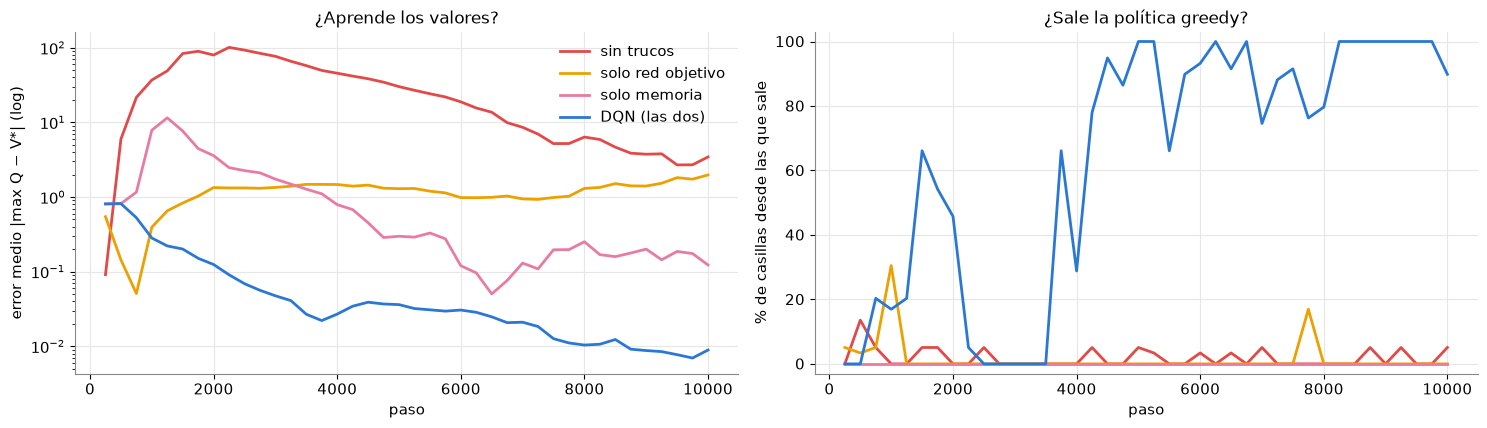

          variante  Q más grande (pico)  error final  sale desde (final)  pasos desde S
        sin trucos               128.83       3.1573                  3%            100
 solo red objetivo                 3.25       1.7634                  0%            100
      solo memoria                13.63       0.1570                  0%            100
     DQN (las dos)                 1.16       0.0080                 97%            100
(final = promedio de las últimas 4 mediciones, del paso 9250 al 10 000; pasos desde S: 100 = no sale)


In [16]:
VARIANTES = {
    "sin trucos":         dict(usar_replay=False, usar_objetivo=False),
    "solo red objetivo":  dict(usar_replay=False, usar_objetivo=True),
    "solo memoria":       dict(usar_replay=True,  usar_objetivo=False),
    "DQN (las dos)":      dict(usar_replay=True,  usar_objetivo=True),
}
COLOR_V = {"sin trucos": COLORES[7], "solo red objetivo": COLORES[3], "solo memoria": COLORES[4], "DQN (las dos)": COLORES[0]}
t0 = time.time()
var = {"sin trucos": sin_trucos}
for nombre, kw in VARIANTES.items():
    if nombre not in var:
        var[nombre] = dqn(env, semilla=SEMILLA, **kw)
print(f"tres variantes más en {time.time() - t0:.1f} s")
print("ε cada mil pasos: " + "  ".join(f"{epsilon(p):.2f}" for p in range(0, 10_001, 1000)))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.4))
for nombre, res in var.items():
    axs[0].plot(res["paso"], res["error"], color=COLOR_V[nombre], label=nombre)
    axs[1].plot(res["paso"], 100 * res["sale"], color=COLOR_V[nombre], label=nombre)
axs[0].set_yscale("log"); axs[0].set_xlabel("paso"); axs[0].set_ylabel("error medio |max Q − V*| (log)")
axs[0].set_title("¿Aprende los valores?"); axs[0].legend(frameon=False)
axs[1].set_ylim(-3, 103); axs[1].set_xlabel("paso"); axs[1].set_ylabel("% de casillas desde las que sale")
axs[1].set_title("¿Sale la política greedy?")
plt.tight_layout(); plt.show()

print(f"{'variante':>18s} {'Q más grande (pico)':>20s} {'error final':>12s} {'sale desde (final)':>19s} {'pasos desde S':>14s}")
for nombre, res in var.items():
    print(f"{nombre:>18s} {res['max_q'].max():>20.2f} {final(res, 'error'):>12.4f} {final(res):>19.0%} {res['pasos_S'][-1]:>14d}")
print("(final = promedio de las últimas 4 mediciones, del paso 9250 al 10 000; pasos desde S: 100 = no sale)")

Cada ingrediente arregla una parte, y hacen falta los dos:

- **Sin trucos**, los valores se disparan a cientos.
- **Solo red objetivo**: el objetivo quieto frena la explosión, pero la red sigue aprendiendo de lo último que vivió y los valores suben despacio por encima de 1; la política no sale.
- **Solo memoria**: los lotes mezclados ayudan, pero el objetivo se mueve con cada paso: los valores se disparan al principio y después bajan, sin llegar a una política que salga.
- **DQN, con las dos**: el error baja a centésimas, el Q más grande queda cerca de 1 y, al final, la política sale desde casi todas las casillas. (Casi: justo desde S, en el paso 10 000, no sale. Lo miramos en el paso 2.)

Al principio, incluso DQN cree que algunas casillas valen un poco más de 1: el $\max$ del objetivo elige justo las flechas que la red sobreestimó. Esa **sobreestimación** es la que atacan variantes como *Double DQN*, que no vemos en este curso.

### Paso 2 — Qué aprendió DQN

Evaluamos la red de DQN en todas las casillas: su $\max_a Q_\theta(s,a)$ y su flecha, al lado del $V^*$ exacto, y el camino que sigue desde S sin explorar.

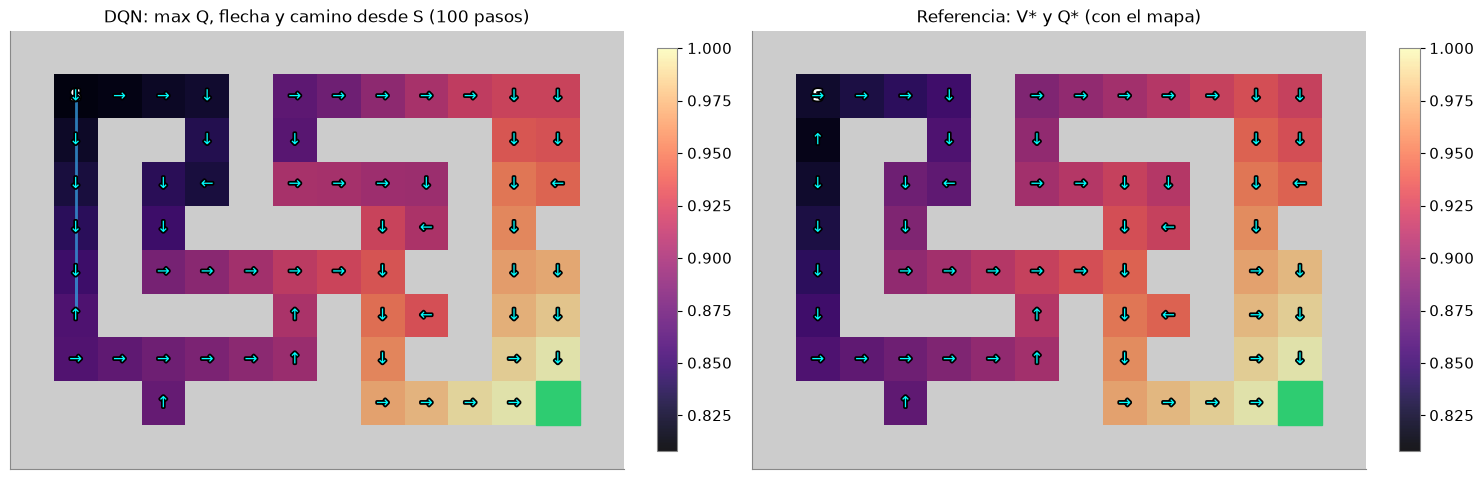

DQN: error medio |max Q − V*| = 0.0089   flechas óptimas: 95%   camino desde S: 100 pasos (el más corto: 20; 100 = no sale)
casillas desde las que la política greedy no sale: 6: [(1, 1), (2, 1), (3, 1), (4, 1), (5, 1), (6, 1)]
el camino desde S termina yendo y viniendo entre (5, 1) y (6, 1):
   (5, 1): la red elige ↓   Q de la red: ↑ 0.8452  → 0.8450  ↓ 0.8509  ← 0.8436   óptima: ↓
   (6, 1): la red elige ↑   Q de la red: ↑ 0.8600  → 0.8562  ↓ 0.8599  ← 0.8546   óptima: ↓


In [17]:
Q_dqn = var["DQN (las dos)"]["Q"]
camino = camino_greedy(env, Q_dqn)
bien_dqn = opt[np.arange(env.nS), Q_dqn.argmax(axis=1)]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
plot_cave(env, values=Q_dqn.max(axis=1), policy=Q_dqn.argmax(axis=1), path=camino, ax=axs[0], clim=CLIM,
          title=f"DQN: max Q, flecha y camino desde S ({len(camino) - 1} pasos)")
plot_cave(env, values=V_estrella, policy=Q_estrella.argmax(axis=1), ax=axs[1], clim=CLIM, title="Referencia: V* y Q* (con el mapa)")
plt.tight_layout(); plt.show()
print(f"DQN: error medio |max Q − V*| = {np.abs(Q_dqn.max(1) - V_estrella)[ng].mean():.4f}   flechas óptimas: {bien_dqn[ng].mean():.0%}   "
      f"camino desde S: {len(camino) - 1} pasos (el más corto: 20; 100 = no sale)")
no_sale = [env.free[s_] for s_ in np.flatnonzero(ng & (pasos_hasta_salir(env, Q_dqn) == 100))]
print(f"casillas desde las que la política greedy no sale: {len(no_sale)}: {no_sale}")
if len(camino) > 100:
    ciclo = sorted(set(camino[-10:]))
    print("el camino desde S termina yendo y viniendo entre " + " y ".join(str(env.free[c]) for c in ciclo) + ":")
    for c in ciclo:
        print(f"   {env.free[c]}: la red elige {ACTION_NAMES[int(Q_dqn[c].argmax())]}   "
              f"Q de la red: " + "  ".join(f"{ACTION_NAMES[b]} {Q_dqn[c, b]:.4f}" for b in range(env.nA))
              + f"   óptima: {', '.join(ACTION_NAMES[b] for b in np.flatnonzero(opt[c]))}")

La red nunca vio el mapa ni a $V^*$: solo coordenadas, bigotes y recompensas. Su mapa de valores se parece al verdadero y la mayoría de sus flechas son óptimas. Pero alcanza con una flecha equivocada en el lugar justo: en (6, 1) la red elige ↑ en vez de ↓ por una diferencia de una diezmilésima, y el camino desde S (y desde toda la columna de la izquierda) queda yendo y viniendo entre (5, 1) y (6, 1). Es lo de la sección 4: en esta cueva, un error chico en el valor alcanza para cambiar una flecha. Y es una foto de un solo momento de una sola semilla, que es lo que discute la sección siguiente.

## 7. Comparar de forma justa: varias semillas

Todo lo anterior salió de **una** semilla: un orden de partidas al azar, unas flechas de exploración, unos pesos iniciales. ¿Y si tuvimos suerte? Para decir que un agente es mejor que otro hace falta, como mínimo, correrlo con varias semillas y mirar las curvas de aprendizaje con su dispersión. (Machado et al., 2018, piden además azar en el entorno, como las acciones pegajosas de la clase 7: si el entorno es determinista, un agente puede memorizar una secuencia en lugar de aprender a jugar.)

### Paso 1 — Cinco semillas de cada uno

Corremos Q-learning con red sin trucos y DQN con 5 semillas cada uno (las semillas 0 a 4; la 0 es la de la sección 6). Las bandas: en el error (escala log), del mínimo al máximo entre semillas, con la mediana; en el porcentaje de casillas desde las que sale, el promedio ± un desvío.

8 corridas más en 35.4 s


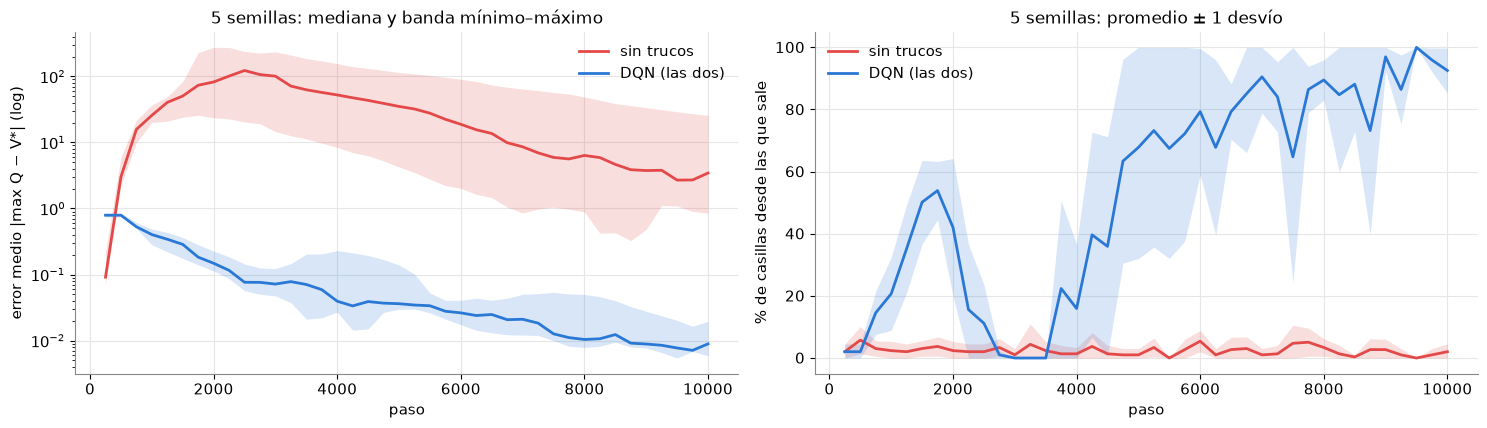

sin trucos:
   sale desde (final): 1% ± 1%   por semilla: ['3%', '1%', '1%', '0%', '0%']
   error final: 10.9167 ± 11.1126   por semilla: [3.1573, 28.3706, 19.8088, 0.9879, 2.2592]
   Q más grande (pico) por semilla: [128.83, 354.43, 163.51, 33.31, 168.16]
DQN (las dos):
   sale desde (final): 94% ± 5%   por semilla: ['97%', '96%', '84%', '96%', '95%']
   error final: 0.0102 ± 0.0050   por semilla: [0.008, 0.0062, 0.02, 0.0097, 0.0073]
   Q más grande (pico) por semilla: [1.16, 1.2, 1.34, 1.19, 1.15]


In [18]:
SEMILLAS = range(5)
t0 = time.time()
corridas = {"sin trucos": [var["sin trucos"]], "DQN (las dos)": [var["DQN (las dos)"]]}
for nombre in corridas:
    for sem in SEMILLAS:
        if sem != SEMILLA:
            corridas[nombre].append(dqn(env, semilla=sem, **VARIANTES[nombre]))
print(f"{2 * (len(SEMILLAS) - 1)} corridas más en {time.time() - t0:.1f} s")

x = var["DQN (las dos)"]["paso"]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4))
for nombre, rs in corridas.items():
    banda_log(axs[0], x, np.array([r["error"] for r in rs]), COLOR_V[nombre], nombre)
    banda(axs[1], x, 100 * np.array([r["sale"] for r in rs]), COLOR_V[nombre], nombre)
axs[0].set_yscale("log"); axs[0].set_xlabel("paso"); axs[0].set_ylabel("error medio |max Q − V*| (log)")
axs[0].set_title("5 semillas: mediana y banda mínimo–máximo"); axs[0].legend(frameon=False)
axs[1].set_ylim(-5, 105); axs[1].set_xlabel("paso"); axs[1].set_ylabel("% de casillas desde las que sale")
axs[1].set_title("5 semillas: promedio ± 1 desvío"); axs[1].legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

for nombre, rs in corridas.items():
    s_ = np.array([final(r) for r in rs]); e_ = np.array([final(r, "error") for r in rs]); m_ = np.array([r["max_q"].max() for r in rs])
    print(f"{nombre}:")
    print(f"   sale desde (final): {s_.mean():.0%} ± {s_.std():.0%}   por semilla: {[format(v, '.0%') for v in s_]}")
    print(f"   error final: {e_.mean():.4f} ± {e_.std():.4f}   por semilla: {[round(float(v), 4) for v in e_]}")
    print(f"   Q más grande (pico) por semilla: {[round(float(v), 2) for v in m_]}")

Con cinco semillas, la diferencia entre los dos no deja dudas: en todas las semillas sin trucos los valores se disparan, y en todas las de DQN el error queda en centésimas. Pero miren la banda de DQN en el porcentaje de casillas desde las que sale: es ancha, la curva promedio sube a los saltos y todas las semillas pasan por un pozo cerca del paso 3000 antes de mejorar. Una semilla sola no cuenta esa parte.

### Paso 2 — Una corrida con suerte contra el promedio

Si hubiéramos corrido DQN una sola vez, ¿qué habríamos contado? Tomamos la **mejor** semilla de DQN en el momento en que mejor le fue, la peor al final, y las comparamos con el promedio de las cinco.

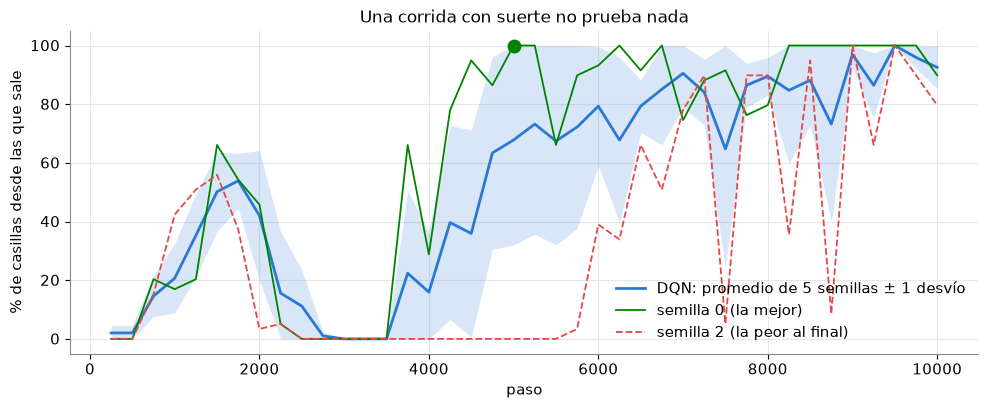

semilla 0, paso 5000: sale desde el 100 % de las casillas
promedio de las 5 semillas en ese mismo paso: 68 % ± 36 %
al final (últimas 4 mediciones): semilla 0 = 97%   semilla 2 = 84%   promedio = 94%


In [19]:
S_dqn = 100 * np.array([r["sale"] for r in corridas["DQN (las dos)"]])
mejor_sem = int(np.argmax(S_dqn.max(axis=1))); peor_sem = int(np.argmin([final(r) for r in corridas["DQN (las dos)"]]))
k_mejor = int(np.argmax(S_dqn[mejor_sem]))

fig, ax = plt.subplots(figsize=(10, 4.2))
banda(ax, x, S_dqn, COLOR_V["DQN (las dos)"], "DQN: promedio de 5 semillas ± 1 desvío")
ax.plot(x, S_dqn[mejor_sem], color=COLORES[5], lw=1.3, label=f"semilla {mejor_sem} (la mejor)")
ax.plot(x, S_dqn[peor_sem], color=COLORES[7], lw=1.3, ls="--", label=f"semilla {peor_sem} (la peor al final)")
ax.plot(x[k_mejor], S_dqn[mejor_sem, k_mejor], "o", color=COLORES[5], ms=9)
ax.set_ylim(-5, 105); ax.set_xlabel("paso"); ax.set_ylabel("% de casillas desde las que sale")
ax.set_title("Una corrida con suerte no prueba nada"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

prom = S_dqn.mean(0)
print(f"semilla {mejor_sem}, paso {x[k_mejor]}: sale desde el {S_dqn[mejor_sem, k_mejor]:.0f} % de las casillas")
print(f"promedio de las 5 semillas en ese mismo paso: {prom[k_mejor]:.0f} % ± {S_dqn[:, k_mejor].std():.0f} %")
print(f"al final (últimas 4 mediciones): semilla {mejor_sem} = {final(corridas['DQN (las dos)'][mejor_sem]):.0%}   "
      f"semilla {peor_sem} = {final(corridas['DQN (las dos)'][peor_sem]):.0%}   "
      f"promedio = {np.mean([final(r) for r in corridas['DQN (las dos)']]):.0%}")

Con la semilla con suerte, en el momento justo, diríamos que DQN «sale desde casi todas las casillas»; el promedio de las cinco en ese mismo paso dice bastante menos, y otra semilla termina más abajo. Ninguna de las dos frases es mentira, pero solo la del promedio con su dispersión sirve para comparar. Para decir que un agente es mejor que otro: **varias semillas, la curva entera con su dispersión (no solo el mejor punto), el mismo presupuesto de pasos para los dos y, si se puede, azar en el entorno**.

## ✍️ Ejercicio — Saquen la red objetivo o la memoria y miren qué pasa

Cambien `USAR_REPLAY` y `USAR_OBJETIVO` y ejecuten. La celda corre esa versión con 3 semillas y la dibuja contra la banda de DQN de la sección 7.

Antes de ejecutar, **predigan**: sin la red objetivo, ¿se disparan los valores en las tres semillas o en algunas? Sin la memoria, ¿la política sale desde alguna casilla? Y si cambian `COPIAR_CADA` (cada cuántos pasos se pone al día la red objetivo) a 400, ¿mejora o empeora?

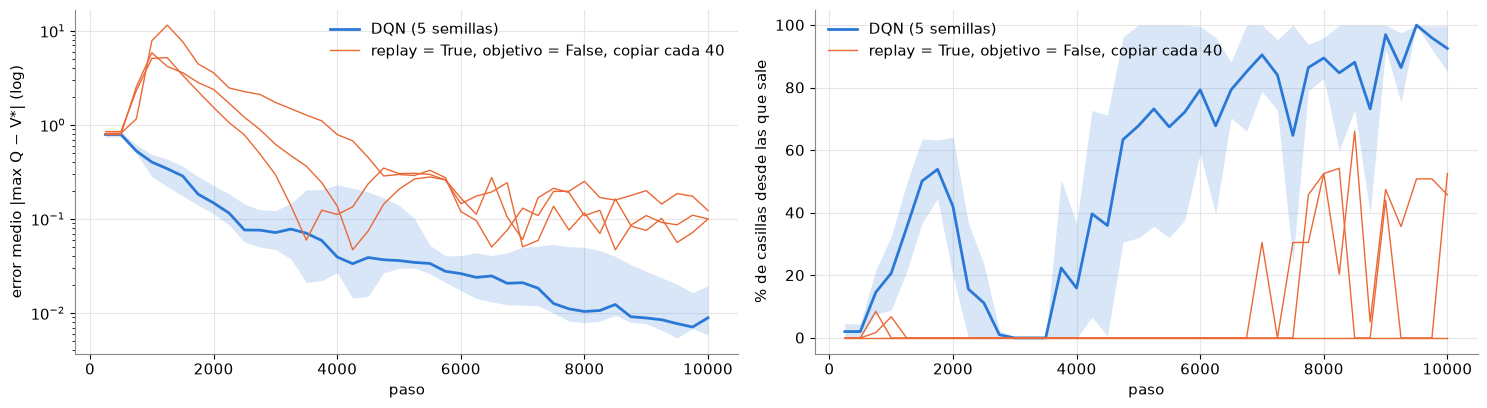

semilla 0: Q más grande (pico) = 13.63   error final = 0.1570   sale desde (final) = 0%
semilla 1: Q más grande (pico) = 6.74   error final = 0.0972   sale desde (final) = 46%
semilla 2: Q más grande (pico) = 7.68   error final = 0.0824   sale desde (final) = 13%


In [20]:
USAR_REPLAY = True      # TODO: probá False
USAR_OBJETIVO = False   # TODO: probá True
COPIAR_CADA = 40        # TODO: probá 400 (con USAR_OBJETIVO = True)

ej = [dqn(env, usar_replay=USAR_REPLAY, usar_objetivo=USAR_OBJETIVO, copiar_cada=COPIAR_CADA, semilla=sem) for sem in range(3)]
nombre_ej = f"replay = {USAR_REPLAY}, objetivo = {USAR_OBJETIVO}, copiar cada {COPIAR_CADA}"
fig, axs = plt.subplots(1, 2, figsize=(15, 4.2))
banda_log(axs[0], x, np.array([r["error"] for r in corridas["DQN (las dos)"]]), COLOR_V["DQN (las dos)"], "DQN (5 semillas)")
banda(axs[1], x, 100 * np.array([r["sale"] for r in corridas["DQN (las dos)"]]), COLOR_V["DQN (las dos)"], "DQN (5 semillas)")
for i, r in enumerate(ej):
    axs[0].plot(x, r["error"], color=COLORES[1], lw=1, label=nombre_ej if i == 0 else None)
    axs[1].plot(x, 100 * r["sale"], color=COLORES[1], lw=1, label=nombre_ej if i == 0 else None)
axs[0].set_yscale("log"); axs[0].set_ylabel("error medio |max Q − V*| (log)"); axs[0].legend(frameon=False)
axs[1].set_ylim(-5, 105); axs[1].set_ylabel("% de casillas desde las que sale"); axs[1].legend(frameon=False, loc="upper left")
for ax in axs:
    ax.set_xlabel("paso")
plt.tight_layout(); plt.show()
for i, r in enumerate(ej):
    print(f"semilla {i}: Q más grande (pico) = {r['max_q'].max():.2f}   error final = {final(r, 'error'):.4f}   sale desde (final) = {final(r):.0%}")

**Lo que encontramos** (¿qué ingrediente frena la explosión de los valores? ¿cuál hace que la política salga? ¿se comportan igual las tres semillas?):

-

## Preguntas para pensar

1. En la sección 4 la red se equivocaba justo al lado de una pared. Si el agente recibiera la imagen de la cueva entera en lugar de coordenadas, ¿seguiría pasando? ¿Qué entrada elegirían para un juego de Atari?
2. La memoria de repetición reusa transiciones viejas, jugadas con una política anterior. ¿Por qué Q-learning puede aprender de ellas y SARSA (clase 6) no tanto?
3. Un artículo dice que su agente «supera a DQN» y muestra una curva de una sola corrida. ¿Qué le pedirían antes de creerle?

In [21]:
print(f"Tiempo total del notebook: {time.time() - T0:.0f} s")

Tiempo total del notebook: 83 s


## Próxima clase

Nuestra red miraba una casilla por vez, con sus coordenadas. El jugador a ciegas no las tiene: si solo siente los bigotes, dos lugares distintos se sienten igual. Cuando lo que se ve no alcanza para saber dónde se está, la red necesita memoria: en la clase 9, **redes recurrentes**, las mismas que leen texto palabra por palabra.